# Medium ablation: why does resistance protect the community in M9CA but not in LB?

**The lab result** (lab meeting, 18 Sep 2026, slides 13–17). With resistant k30 present:

- in **M9CA**, the community recovers toward its untreated state and keeps its diversity;
- in **LB**, the susceptible populations decline *faster* during the first two hours of treatment (4 → 6 h, total biomass excluding k30), and richness is still lower at 48 h, which the slides read as persistent strain loss.

The takeaway slide frames it as a race: in M9CA, detoxification outpaces susceptible loss; in LB, it does not.

**The modelling question.** LB differs from M9CA in several ways at once. Which of those differences, switched one at a time and in combination, can turn the M9CA outcome into the LB outcome?

**A warning from the model's README.** There is deliberately no "LB" preset. An earlier version hid a 90× killing factor inside its LB preset, and a conclusion was wrongly attributed to growth rate as a result. So here every difference is a named, separately switchable parameter:

| Difference | M9CA (baseline) | LB | Evidence for the LB value |
|---|---|---|---|
| maximum growth rate `growth_mean` | 0.55 /h | 1.40 /h | model README, "roughly" |
| nutrient supply `food` | 1.0 OD-eq | 2.5 OD-eq | model README, "roughly" |
| lag after inoculation and transfer `lag_h` | 0 h | ? | not measured; new parameter |
| enzyme activity per OD of carrier `vmax` | 10 000 | ? | not measured |
| killing per unit growth `gamma` | 2.5 | ? | not measured |
| susceptible IC50 `susceptible_ic50` | 5 µg/ml | ? | MICs are medium-dependent; not measured |

The first two are the only differences with any support, so the analysis asks: *given LB's faster growth and richer food, what else would have to differ to reproduce the lab result, and by how much?*

**Lag phase** (new in the model). `lag_h` uses the Baranyi–Roberts form, the standard way of adding lag to growth models: growth is multiplied by $\alpha(t)=q/(1+q)$ with $dq/dt=\mu\,q$. Equivalently,
$$\alpha(t)=\frac{1}{1+\left(e^{\mu L}-1\right)e^{-\mu (t-t_0)}},$$
where $L$ = `lag_h`, $\mu$ = `growth_mean` and $t_0$ is when the culture entered fresh medium (inoculation at 0 h, transfer at 24 h). Because killing is proportional to growth in this model, cells still in lag are automatically drug-tolerant, matching "tolerance by lag" (Fridman et al. 2014, *Nature* 513:418).

**Lab-comparable readouts**

- `protected_change_4_6h`: biomass of the non-carrier strains at 6 h ÷ at 4 h, in the treated community with k30 (the lab's 4 → 6 h panel).
- `protected_richness`: non-carrier strains above the detection limit at 48 h (of 56). `protected_extinct` counts those that are truly gone (below one cell). The difference is strains that survive but are too rare to detect.

A scenario is called **lab-like** when, compared with the M9CA baseline, the non-carrier strains decline faster from 4 to 6 h *and* fewer of them are detected at 48 h.

In [1]:
import itertools
import sys
from math import factorial
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))          # resilience_model.py lives one level up
from resilience_model import run, sweep, grid, check, BASELINE, SAMPLE_HOURS

OUT = Path("medium_ablation_results")
(OUT / "figures").mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "grid.linewidth": 0.6, "lines.linewidth": 2.0})
BLUE, ORANGE, GREEN, VERMILION, PURPLE, SKY, GREY = (
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#7F7F7F")

checks = check(verbose=False)
print(f"{int(checks.passed.sum())}/{len(checks)} model sanity checks passed")
assert checks.passed.all(), checks[~checks.passed]

M9CA = {}                                            # the model baseline is M9CA
LB_KNOWN = dict(growth_mean=1.40, food=2.5)          # the two supported LB differences
DOSES = [50.0, 70.0]
REF = {d: run(dose=d).metrics for d in DOSES}        # M9CA reference at each dose


def save(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png", dpi=150, bbox_inches="tight")


def lab_like(m, dose):
    """Faster 4->6 h decline of the non-carrier strains AND fewer detected at 48 h."""
    return bool(m.protected_change_4_6h < REF[dose].protected_change_4_6h and
                m.protected_richness < REF[dose].protected_richness)


def heatmap(ax, df, x, y, z, cmap="Blues", vmin=None, vmax=None, fmt="{:g}"):
    pv = df.pivot_table(index=y, columns=x, values=z, dropna=False)
    cm = plt.get_cmap(cmap).copy(); cm.set_bad("#D9D9D9")
    im = ax.pcolormesh(np.arange(pv.shape[1] + 1), np.arange(pv.shape[0] + 1),
                       np.ma.masked_invalid(pv.values), cmap=cm, vmin=vmin, vmax=vmax,
                       shading="flat", edgecolors="white", linewidth=0.5)
    ax.set_xticks(np.arange(pv.shape[1]) + .5)
    ax.set_xticklabels([fmt.format(v) for v in pv.columns], fontsize=7)
    ax.set_yticks(np.arange(pv.shape[0]) + .5)
    ax.set_yticklabels([fmt.format(v) for v in pv.index], fontsize=7)
    ax.grid(False)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.values[i, j]
            if np.isfinite(v):
                ax.text(j + .5, i + .5, f"{v:.0f}", ha="center", va="center", fontsize=6.5,
                        color="white" if (v - (vmin or 0)) / ((vmax or 1) - (vmin or 0)) > .55
                        else "0.2")
    return im


KEY = ["protected_richness", "protected_extinct", "protected_change_4_6h",
       "protected_biomass_ratio", "resistant_share", "compositional_resilience",
       "shannon_resilience", "drug_clearance_h"]

20/20 model sanity checks passed


## 1. The supported differences: faster growth and richer food

A 2 × 2 of `growth_mean` and `food` at both doses, with everything else at M9CA values.

In [2]:
rows = []
for dose in DOSES:
    for g_name, g in [("M9CA growth", {}), ("LB growth", dict(growth_mean=1.40))]:
        for f_name, f in [("M9CA food", {}), ("LB food", dict(food=2.5))]:
            m = run(dose=dose, **g, **f).metrics
            rows.append({"dose": dose, "growth": g_name, "food": f_name,
                         **m[KEY].to_dict(), "lab_like": lab_like(m, dose)})
known = pd.DataFrame(rows)
known.to_csv(OUT / "01_growth_x_food.csv", index=False)
with pd.option_context("display.width", 220):
    print(known.round(3).to_string(index=False))

# the state of the culture when the drug arrives
state = []
for name, kw in [("M9CA", M9CA), ("LB (growth + food)", LB_KNOWN)]:
    sim = run(**kw).control
    i = int(np.argmin(np.abs(sim["t"] - BASELINE.pregrowth_h)))
    food0 = kw.get("food", BASELINE.food)
    state.append(dict(medium=name, OD_at_drug=sim["N"][i].sum(),
                      food_left_fraction=sim["R"][i] / food0,
                      k30_OD_at_drug=sim["N"][i][BASELINE.focal_index]))
state = pd.DataFrame(state)
print("\nWhen the drug is added at 4 h:")
print(state.round(4).to_string(index=False))

 dose      growth      food  protected_richness  protected_extinct  protected_change_4_6h  protected_biomass_ratio  resistant_share  compositional_resilience  shannon_resilience  drug_clearance_h  lab_like
 50.0 M9CA growth M9CA food                  56                  0                  0.212                    0.565            0.442                     0.567               0.732               3.3     False
 50.0 M9CA growth   LB food                  56                  0                  0.202                    0.593            0.414                     0.593               0.760               3.2     False
 50.0   LB growth M9CA food                  56                  0                  0.903                    0.997            0.014                     0.998               1.000               0.4     False
 50.0   LB growth   LB food                  56                  0                  1.284                    0.983            0.026                     0.959               1.00

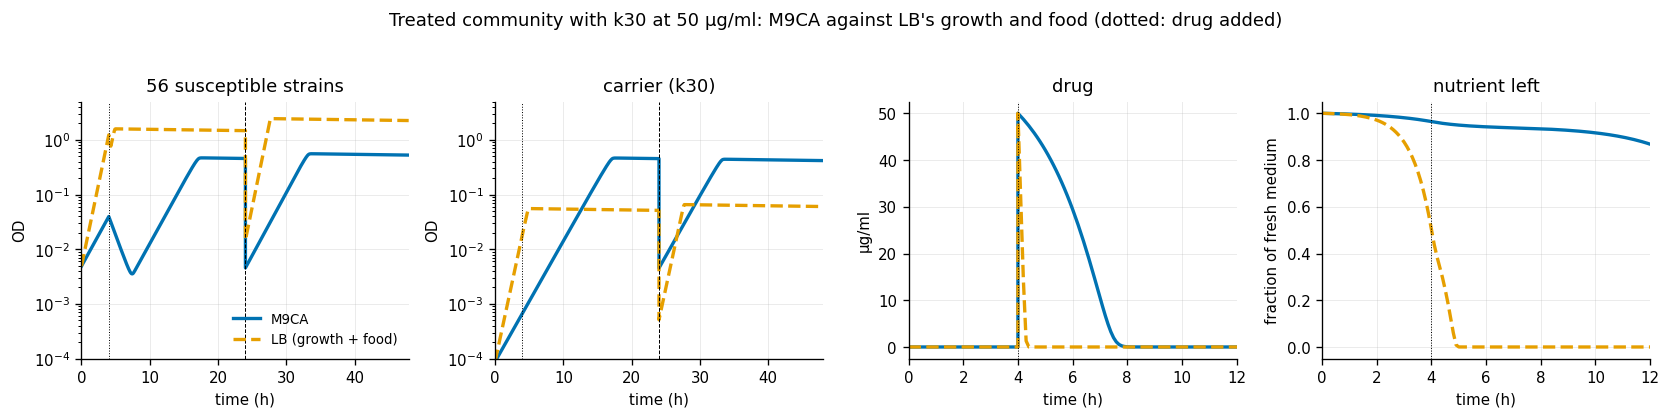

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.3))
for name, kw, color, ls in [("M9CA", M9CA, BLUE, "-"), ("LB (growth + food)", LB_KNOWN, ORANGE, "--")]:
    r = run(dose=50.0, **kw)
    sim, car = r.treated, r.treated["carrier"]
    food0 = kw.get("food", BASELINE.food)
    axs[0].plot(sim["t"], np.maximum(sim["N"][:, ~car].sum(1), 1e-10), color=color, ls=ls, label=name)
    axs[1].plot(sim["t"], np.maximum(sim["N"][:, car].sum(1), 1e-10), color=color, ls=ls, label=name)
    axs[2].plot(sim["t"], sim["a"], color=color, ls=ls, label=name)
    axs[3].plot(sim["t"], sim["R"] / food0, color=color, ls=ls, label=name)
axs[0].set(yscale="log", ylim=(1e-4, 5), ylabel="OD", title="56 susceptible strains")
axs[1].set(yscale="log", ylim=(1e-4, 5), ylabel="OD", title="carrier (k30)")
axs[2].set(ylabel="µg/ml", title="drug", xlim=(0, 12))
axs[3].set(ylabel="fraction of fresh medium", title="nutrient left", xlim=(0, 12))
for ax in axs:
    ax.axvline(BASELINE.pregrowth_h, color="k", lw=.6, ls=":"); ax.set_xlabel("time (h)")
for ax in axs[:2]:
    ax.axvline(24, color="k", lw=.6, ls="--"); ax.set_xlim(0, 48)
axs[0].legend(frameon=False, fontsize=8)
fig.suptitle("Treated community with k30 at 50 µg/ml: M9CA against LB's growth and food "
             "(dotted: drug added)", y=1.04)
fig.tight_layout(); save(fig, "01_known_differences_timecourse"); plt.show()

### The supported differences alone predict the *opposite* of the lab result

With only LB's faster growth and richer food, the model's LB community does **better** than M9CA, not worse. All 56 susceptible strains survive in both. In LB, though, their biomass *grows* from 4 to 6 h (× 1.28, against × 0.21 in M9CA), k30 stays rare (share 0.03, against 0.44) and the community ends close to its untreated state (compositional resilience 0.96, against 0.57).

**Why.** Faster growth means the culture is much further along when the drug arrives at 4 h: 1.25 OD in LB against 0.04 OD in M9CA, with about 26× more k30 biomass. That much enzyme clears the drug in about 0.3 h instead of 3.3 h. And because half of LB's food is already used by 4 h and it runs out by about 5 h, the cells stop growing soon after the drug arrives. Killing needs growth, so they become tolerant. Growth rate does almost all of this; richer food alone barely changes anything.

So if LB's only differences were growth and food, the model would predict *better* protection in LB. Something else must differ. (This also depends on the model's LB culture really being at about 1.25 OD at 4 h, which is directly measurable.)

## 2. One unknown difference at a time

Each candidate is scanned on **both** backgrounds: M9CA, and LB's growth and food. Killing per growth is scaled up, enzyme activity per OD is scaled down, lag is lengthened, and IC50 is lowered (more sensitive strains). Dose 50 µg/ml. The dashed grey line in the bottom row is the M9CA baseline's 4 → 6 h change; below it means a faster early decline than M9CA.

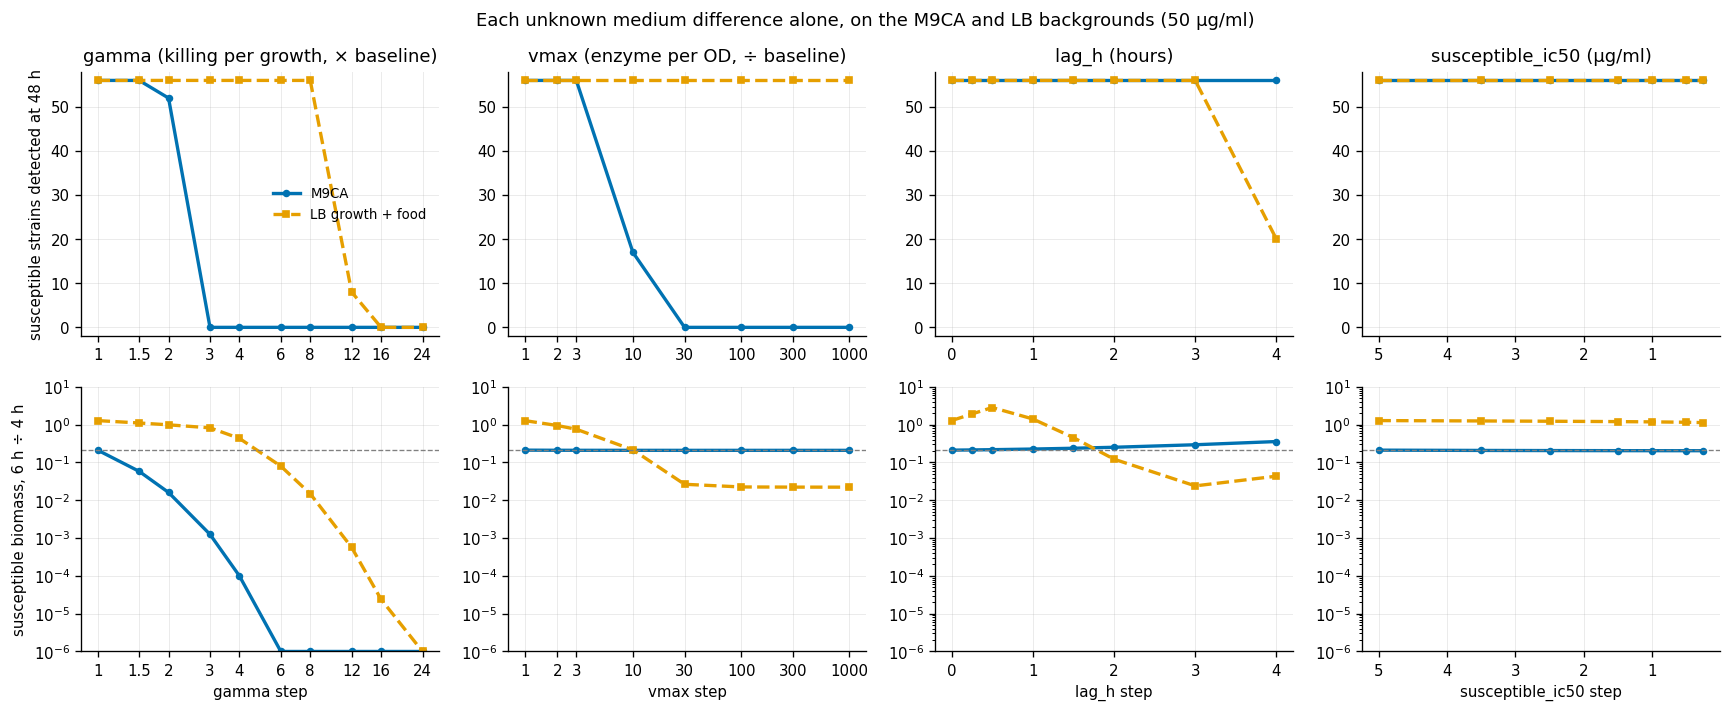

Smallest step (within the scanned range) at which strains are lost:
                                                         first strain lost at step  half lost at step  any lab-like step
factor                                 background                                                                       
gamma (killing per growth, × baseline) M9CA                                    2.0                3.0               True
                                       LB growth + food                       12.0               12.0               True
vmax (enzyme per OD, ÷ baseline)       M9CA                                   10.0               10.0               True
                                       LB growth + food                        NaN                NaN              False
lag_h (hours)                          M9CA                                    NaN                NaN              False
                                       LB growth + food                        4.0   

In [4]:
SCANS = {
    "gamma (killing per growth, × baseline)":
        ("gamma", [1, 1.5, 2, 3, 4, 6, 8, 12, 16, 24], lambda k: 2.5 * k),
    "vmax (enzyme per OD, ÷ baseline)":
        ("vmax", [1, 2, 3, 10, 30, 100, 300, 1000], lambda k: 1e4 / k),
    "lag_h (hours)":
        ("lag_h", [0, 0.25, 0.5, 1, 1.5, 2, 3, 4], lambda k: k),
    "susceptible_ic50 (µg/ml)":
        ("susceptible_ic50", [5, 3.5, 2.5, 1.5, 1, 0.5, 0.25], lambda k: k),
}
BACKS = {"M9CA": (M9CA, BLUE, "-o"), "LB growth + food": (LB_KNOWN, ORANGE, "--s")}

rows = []
for label, (par, steps, to_value) in SCANS.items():
    for back, (kw, _, _) in BACKS.items():
        for k in steps:
            m = run(**kw, **{par: to_value(k)}).metrics
            rows.append({"factor": label, "parameter": par, "step": k, "value": to_value(k),
                         "background": back, **m[KEY].to_dict(), "lab_like": lab_like(m, 50.0)})
single = pd.DataFrame(rows)
single.to_csv(OUT / "02_one_factor_scans.csv", index=False)

fig, axs = plt.subplots(2, 4, figsize=(14.5, 6))
for j, (label, (par, steps, _)) in enumerate(SCANS.items()):
    for back, (_, color, style) in BACKS.items():
        s = single[(single.factor == label) & (single.background == back)]
        axs[0, j].plot(s.step, s.protected_richness, style, ms=3.5, color=color, label=back)
        axs[1, j].plot(s.step, np.maximum(s.protected_change_4_6h, 1e-6), style, ms=3.5,
                       color=color, label=back)
    axs[1, j].axhline(REF[50.0].protected_change_4_6h, color="0.5", lw=.8, ls="--")
    axs[0, j].set(ylim=(-2, 58), title=label)
    axs[1, j].set(yscale="log", ylim=(1e-6, 10), xlabel=label.split(" (")[0] + " step")
    if par in ("gamma", "vmax"):
        for ax in axs[:, j]:
            ax.set_xscale("log"); ax.set_xticks(steps); ax.set_xticklabels([f"{v:g}" for v in steps])
            ax.minorticks_off()
    if par == "susceptible_ic50":
        for ax in axs[:, j]:
            ax.invert_xaxis()
axs[0, 0].set_ylabel("susceptible strains detected at 48 h")
axs[1, 0].set_ylabel("susceptible biomass, 6 h ÷ 4 h")
axs[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Each unknown medium difference alone, on the M9CA and LB backgrounds (50 µg/ml)")
fig.tight_layout(); save(fig, "02_one_factor_scans"); plt.show()

def threshold(s, lost):
    hit = s[s.protected_richness <= 56 - lost]
    return hit.step.iloc[0] if len(hit) else np.nan

thr = (single.groupby(["factor", "background"], sort=False)
       .apply(lambda s: pd.Series({"first strain lost at step": threshold(s, 1),
                                   "half lost at step": threshold(s, 28),
                                   "any lab-like step": bool(s.lab_like.any())}),
              include_groups=False))
print("Smallest step (within the scanned range) at which strains are lost:")
print(thr.to_string())

### What one difference at a time shows

- **IC50 does nothing.** At 50 µg/ml the drug is far above every strain's IC50, so killing is already saturated; making strains more sensitive changes nothing.
- **The M9CA community is fragile; the LB community is robust.** On M9CA, doubling `gamma` loses strains (52 survive) and tripling it loses all of them. Cutting `vmax` tenfold leaves 17. On the LB background, `gamma` must rise 12-fold before strains are lost, a 4 h lag is needed, and no reduction of `vmax` (down to 1/1000) loses a single strain. The LB culture runs out of food within about an hour of the drug arriving, and the drug can only kill while cells grow.
- **Lag acts in opposite directions in the two media.** In M9CA a lag only makes cells more tolerant (no strain is lost even with 4 h). In LB, a long lag delays growth until the drug is there and, with enough of it, causes loss. A short lag (0.5 h) in LB actually *raises* the 4 → 6 h change.
- **The early decline is easier to reproduce than strain loss.** The non-carrier strains decline faster than in M9CA from `gamma` × 6, `vmax` ÷ 30 or a 2 h lag on the LB background (orange curve below the dashed line), all well short of the values needed to lose strains.

The only single changes that reproduce both lab observations in LB are a 12-fold increase in killing per growth or a 4 h lag. Both are large. The next section asks whether smaller changes in combination suffice.

## 3. Two unknown differences together, on the LB background

Pairs of the three candidates that mattered in section 2, at 50 µg/ml. Each cell is the number of susceptible strains detected at 48 h (of 56).

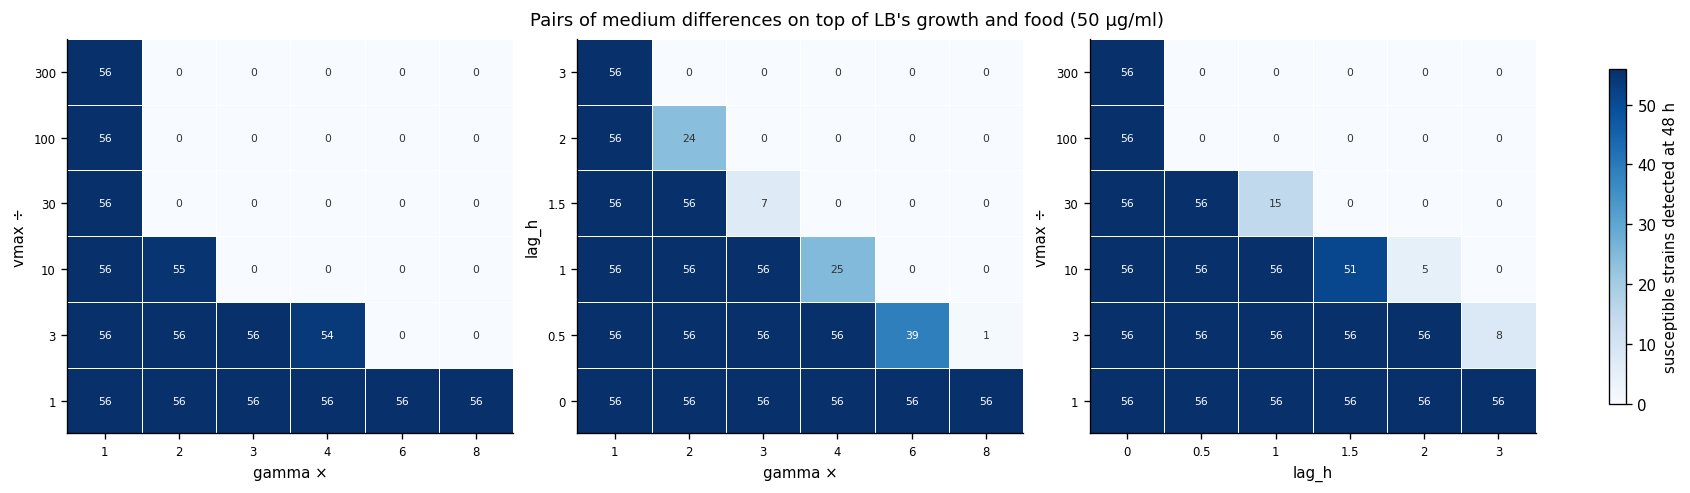

In [5]:
GMUL = [1, 2, 3, 4, 6, 8]
VDIV = [1, 3, 10, 30, 100, 300]
LAGS = [0, 0.5, 1, 1.5, 2, 3]
pairs = {
    ("gamma ×", "vmax ÷"): [dict(gamma=2.5 * a, vmax=1e4 / b) for a in GMUL for b in VDIV],
    ("gamma ×", "lag_h"): [dict(gamma=2.5 * a, lag_h=b) for a in GMUL for b in LAGS],
    ("lag_h", "vmax ÷"): [dict(lag_h=a, vmax=1e4 / b) for a in LAGS for b in VDIV],
}
axes_vals = {("gamma ×", "vmax ÷"): (GMUL, VDIV), ("gamma ×", "lag_h"): (GMUL, LAGS),
             ("lag_h", "vmax ÷"): (LAGS, VDIV)}
pair_rows = []
for key, settings in pairs.items():
    xs, ys = axes_vals[key]
    for (a, b), kw in zip(itertools.product(xs, ys), settings):
        m = run(**LB_KNOWN, **kw).metrics
        pair_rows.append({"pair": " & ".join(key), "x": a, "y": b, **m[KEY].to_dict(),
                          "lab_like": lab_like(m, 50.0)})
pair_df = pd.DataFrame(pair_rows)
pair_df.to_csv(OUT / "03_pairwise_on_LB.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, key in zip(axs, pairs):
    d = pair_df[pair_df.pair == " & ".join(key)]
    im = heatmap(ax, d, "x", "y", "protected_richness", vmin=0, vmax=56)
    ax.set(xlabel=key[0], ylabel=key[1])
fig.colorbar(im, ax=axs, shrink=.85, label="susceptible strains detected at 48 h")
fig.suptitle("Pairs of medium differences on top of LB's growth and food (50 µg/ml)")
save(fig, "03_pairwise_on_LB"); plt.show()

### Moderate differences act together

The pairs interact strongly. On the LB background, `gamma` × 4 alone and `vmax` ÷ 10 alone each lose no strains, but together they lose all 56. Likewise `gamma` × 3 with a 1.5 h lag leaves 7, and a 1.5 h lag with `vmax` ÷ 30 leaves none. In every panel the boundary between rescue and collapse runs diagonally, so a modest difference in each of two properties is as effective as a large difference in one.

## 4. The full ablation: every combination of five switches

Each switch moves one property from its M9CA value to an LB value: **growth**, **food**, **lag**, **vmax** (enzyme per OD) and **gamma** (killing per growth). All 2⁵ = 32 combinations are run at both doses. IC50 is left out because section 2 showed it has almost no effect.

The three unknowns have no measured LB value, so the ablation is repeated at three magnitudes:

| Set | lag (LB only) | vmax | gamma |
|---|---|---|---|
| mild | 0.5 h | ÷ 3 | × 2 |
| moderate | 1 h | ÷ 10 | × 4 |
| strong | 2 h | ÷ 30 | × 8 |

**Attributing the change to each switch.** With every combination available, each switch's contribution can be computed exactly as its *Shapley value*: the change it causes when switched on, averaged over every order in which the five switches could be applied (equivalently, over every combination of the others). The contributions add up exactly to the full M9CA → LB difference, so none of the effect is left unassigned or double-counted. Two outcomes are attributed: susceptible strains lost (detected at 48 h), and the early decline, log₁₀ of the 4 → 6 h biomass change.

In [6]:
SWITCHES = ["growth", "food", "lag", "vmax", "gamma"]
SETS = {"mild": dict(lag=0.5, vdiv=3, gmul=2),
        "moderate": dict(lag=1.0, vdiv=10, gmul=4),
        "strong": dict(lag=2.0, vdiv=30, gmul=8)}


def medium(on, mag):
    kw = {}
    if "growth" in on: kw["growth_mean"] = 1.40
    if "food" in on: kw["food"] = 2.5
    if "lag" in on: kw["lag_h"] = mag["lag"]
    if "vmax" in on: kw["vmax"] = 1e4 / mag["vdiv"]
    if "gamma" in on: kw["gamma"] = 2.5 * mag["gmul"]
    return kw


rows = []
for set_name, mag in SETS.items():
    for dose in DOSES:
        for k in range(len(SWITCHES) + 1):
            for on in itertools.combinations(SWITCHES, k):
                m = run(dose=dose, **medium(on, mag)).metrics
                rows.append({"set": set_name, "dose": dose, "switches": " + ".join(on) or "(M9CA)",
                             "n_switches": k, **{s: s in on for s in SWITCHES},
                             **m[KEY].to_dict(), "lab_like": lab_like(m, dose)})
fact = pd.DataFrame(rows)
fact["strains_lost"] = 56 - fact.protected_richness
fact["early_log10"] = np.log10(np.maximum(fact.protected_change_4_6h, 1e-6))
fact.to_csv(OUT / "04_factorial.csv", index=False)


def shapley(d, outcome):
    v = {frozenset(s for s in SWITCHES if r[s]): r[outcome] for _, r in d.iterrows()}
    n, phi = len(SWITCHES), {}
    for i in SWITCHES:
        others = [s for s in SWITCHES if s != i]
        tot = 0.0
        for k in range(n):
            for S in itertools.combinations(others, k):
                S = frozenset(S)
                tot += factorial(k) * factorial(n - k - 1) / factorial(n) * (v[S | {i}] - v[S])
        phi[i] = tot
    return phi


shap = pd.DataFrame([{"set": s, "dose": d, "outcome": o, **shapley(g, o)}
                     for (s, d), g in fact.groupby(["set", "dose"], sort=False)
                     for o in ("strains_lost", "early_log10")])
shap.to_csv(OUT / "04_shapley.csv", index=False)
full = fact[fact.n_switches == 5].set_index(["set", "dose"])
print("All five switches on (the full M9CA -> LB move):")
print(full[["protected_richness", "protected_extinct", "protected_change_4_6h",
            "resistant_share"]].round(4).to_string())
print("\nShapley contributions (sum = full M9CA -> LB change):")
print(shap.round(2).to_string(index=False))

All five switches on (the full M9CA -> LB move):
               protected_richness  protected_extinct  protected_change_4_6h  resistant_share
set      dose                                                                               
mild     50.0                  56                  0                 0.0313           0.8364
         70.0                  56                  0                 0.0089           0.9488
moderate 50.0                   0                 56                 0.0000           1.0000
         70.0                   0                 56                 0.0000           1.0000
strong   50.0                   0                 56                 0.0000           1.0000
         70.0                   0                 56                 0.0000           1.0000

Shapley contributions (sum = full M9CA -> LB change):
     set  dose      outcome  growth  food   lag  vmax  gamma
    mild  50.0 strains_lost  -21.03 -0.20  1.80  6.97  12.47
    mild  50.0  early_log10   

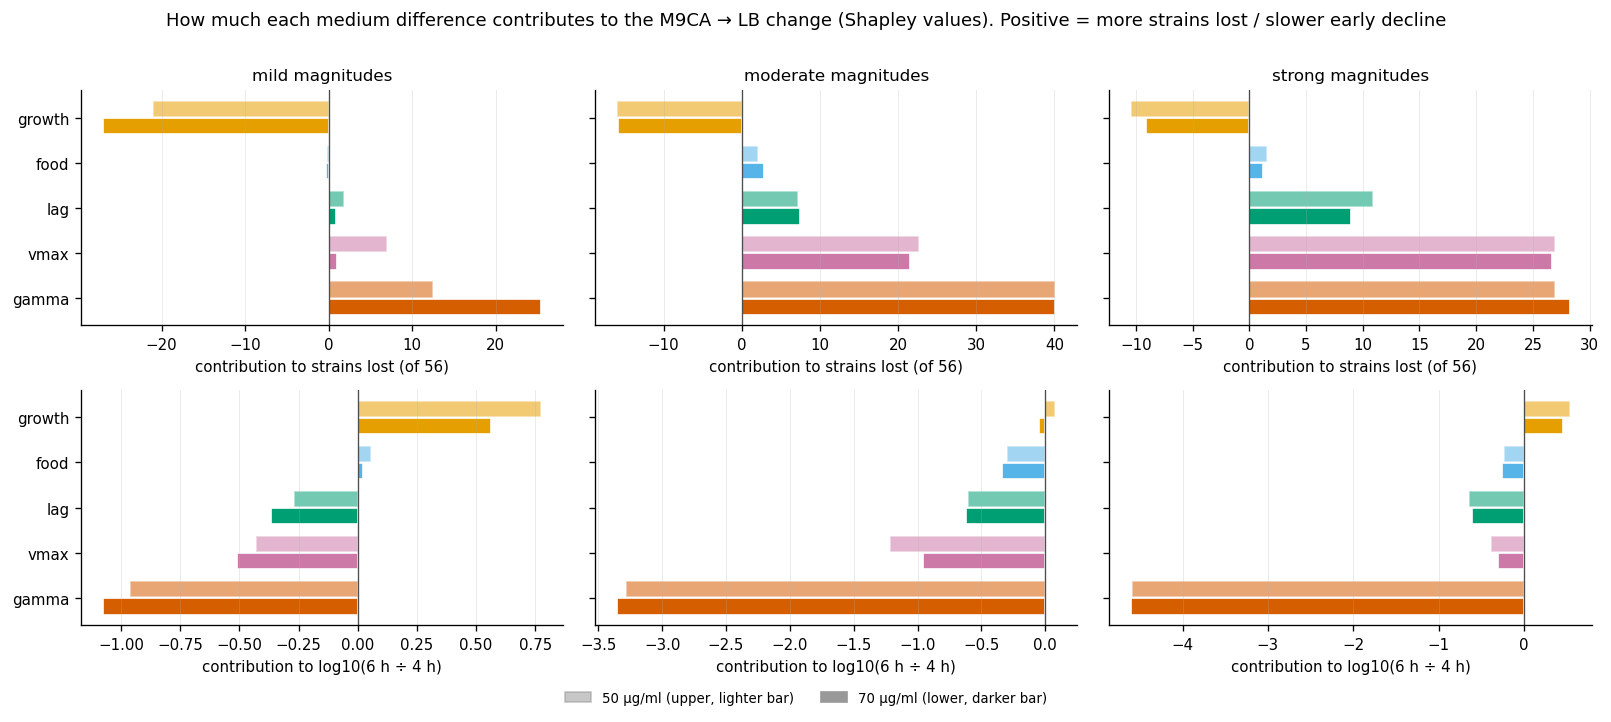

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(13.5, 5.6), sharey="row")
sw_colors = dict(zip(SWITCHES, [ORANGE, SKY, GREEN, PURPLE, VERMILION]))
ypos = np.arange(len(SWITCHES))
for j, set_name in enumerate(SETS):
    for i, (outcome, label) in enumerate([("strains_lost", "contribution to strains lost (of 56)"),
                                          ("early_log10", "contribution to log10(6 h ÷ 4 h)")]):
        ax = axs[i, j]
        for k, (dose, alpha) in enumerate(zip(DOSES, [0.55, 1.0])):
            r = shap[(shap.set == set_name) & (shap.dose == dose) & (shap.outcome == outcome)].iloc[0]
            vals = [r[s] for s in SWITCHES]
            ax.barh(ypos + (k - .5) * .38, vals, height=.36, alpha=alpha,
                    color=[sw_colors[s] for s in SWITCHES], edgecolor="white",
                    label=f"{dose:g} µg/ml")
        ax.axvline(0, color="0.3", lw=.8)
        ax.set_yticks(ypos); ax.set_yticklabels(SWITCHES)
        ax.grid(axis="y", visible=False); ax.set_xlabel(label)
        if i == 0:
            ax.set_title(f"{set_name} magnitudes", fontsize=10)
axs[0, 0].invert_yaxis(); axs[1, 0].invert_yaxis()
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="0.6", alpha=.55, label="50 µg/ml (upper, lighter bar)"),
                    Patch(color="0.6", alpha=1.0, label="70 µg/ml (lower, darker bar)")],
           frameon=False, fontsize=8, loc="lower center", ncol=2, bbox_to_anchor=(.5, -.04))
fig.suptitle("How much each medium difference contributes to the M9CA → LB change (Shapley values). "
             "Positive = more strains lost / slower early decline", y=1.01)
fig.tight_layout(); save(fig, "04_shapley"); plt.show()

In [8]:
# Which combinations reproduce the lab result? Only combinations that include LB's growth and
# food are realistic (those differences are known), so list the smallest such combinations.
realistic = fact[fact.growth & fact.food]
hits = realistic[realistic.lab_like]
print("Lab-like combinations that include LB's growth and food (fewest switches first):")
with pd.option_context("display.width", 220):
    print(hits.sort_values(["set", "dose", "n_switches"])
          [["set", "dose", "switches", "protected_richness", "protected_extinct",
            "protected_change_4_6h", "resistant_share"]].round(4).to_string(index=False))

summary = (realistic.groupby(["set", "dose"], sort=False)
           .apply(lambda g: pd.Series({
               "lab-like combinations": int(g.lab_like.sum()),
               "of": len(g),
               "growth + food alone lab-like?": bool(g[g.n_switches == 2].lab_like.iloc[0])}),
               include_groups=False))
print("\nPer magnitude set and dose:")
print(summary.to_string())

Lab-like combinations that include LB's growth and food (fewest switches first):
     set  dose                           switches  protected_richness  protected_extinct  protected_change_4_6h  resistant_share
moderate  50.0        growth + food + lag + gamma                  25                  0                 0.0013           0.9941
moderate  50.0       growth + food + vmax + gamma                   0                 31                 0.0000           1.0000
moderate  50.0 growth + food + lag + vmax + gamma                   0                 56                 0.0000           1.0000
moderate  70.0        growth + food + lag + gamma                   0                  0                 0.0001           1.0000
moderate  70.0       growth + food + vmax + gamma                   0                 56                 0.0000           1.0000
moderate  70.0 growth + food + lag + vmax + gamma                   0                 56                 0.0000           1.0000
  strong  50.0  

### What the full ablation shows

- **Growth rate protects; the unknowns must outweigh it.** In every magnitude set, switching to LB's growth rate *reduces* strains lost (Shapley values −9 to −27 strains), and food contributes almost nothing. The harmful contributions come from the three unknowns.
- **Killing per growth (`gamma`) is the largest single contributor.** It dominates the loss of strains at mild and moderate magnitudes (12–40 strains) and ties with `vmax` at strong magnitudes (about 27 each). Lag contributes less (1–11 strains).
- **`gamma` dominates the early decline in every set.** Its contribution to the 4 → 6 h change is −1.0 to −4.6 log₁₀ units, several times that of `vmax` or lag, while LB's growth rate pushes the other way. Since the faster early decline is the lab's most direct observation, **higher killing per unit growth in LB is the leading candidate in this model**, with weaker enzyme activity per cell or a lag as plausible partners.
- **No lab-like combination needs fewer than two unknowns** on top of LB's growth and food, except at strong magnitudes and 70 µg/ml, where `gamma` × 8 alone suffices. With all five switches at mild magnitudes, the early decline is already faster than in M9CA (× 0.03 against × 0.21) but no strain is lost.

**Caveat.** The LB values of the unknowns are assumptions, and Shapley values depend on them; that is why three magnitude sets are shown. The ranking (`gamma` first for the early decline; growth always protective) is the same in all three.

## 5. Strain loss or just below detection?

The lab reads LB's 48 h richness drop as persistent strain loss. In the model the two can be told apart: a strain counted as missing may be truly extinct (below one cell) or alive but below the sequencing detection limit (10⁻⁴ relative abundance by default). When k30 dominates, the others can fall below detection without dying.

Below: richness over the lab's sampling times (4, 6, 24, 48 h) for M9CA and three lab-like LB scenarios from section 4. Each is shown at two detection limits, with the number truly extinct.

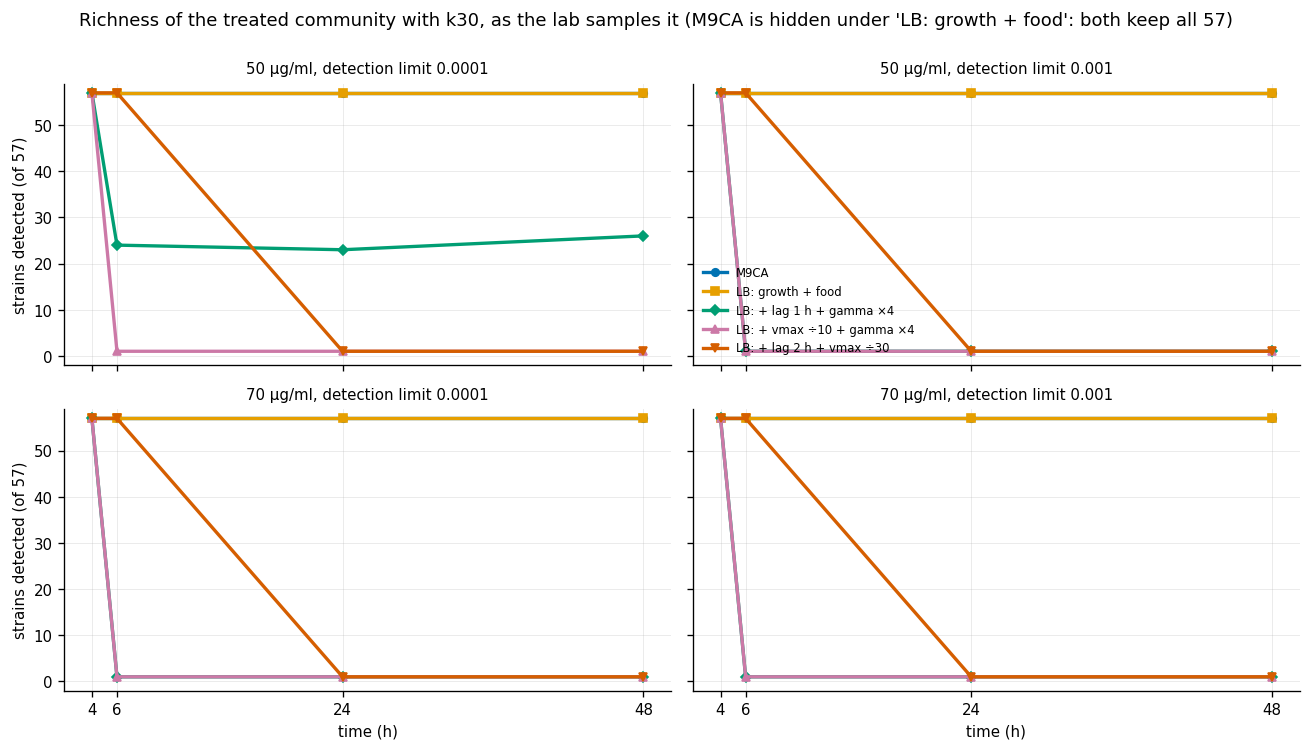

Treated community at 48 h: strains detected at each limit, and strains truly extinct
                               detected        extinct       
detection                        0.0001 0.0010  0.0001 0.0010
scenario                  dose                               
M9CA                      50.0     57.0   57.0     0.0    0.0
                          70.0     57.0   57.0     0.0    0.0
LB: growth + food         50.0     57.0   57.0     0.0    0.0
                          70.0     57.0   57.0     0.0    0.0
LB: + lag 1 h + gamma ×4  50.0     26.0    1.0     0.0    0.0
                          70.0      1.0    1.0     0.0    0.0
LB: + vmax ÷10 + gamma ×4 50.0      1.0    1.0    31.0   31.0
                          70.0      1.0    1.0    56.0   56.0
LB: + lag 2 h + vmax ÷30  50.0      1.0    1.0     0.0    0.0
                          70.0      1.0    1.0     0.0    0.0


In [9]:
SCEN = {
    "M9CA": M9CA,
    "LB: growth + food": LB_KNOWN,
    "LB: + lag 1 h + gamma ×4": dict(**LB_KNOWN, lag_h=1.0, gamma=10.0),
    "LB: + vmax ÷10 + gamma ×4": dict(**LB_KNOWN, vmax=1e3, gamma=10.0),
    "LB: + lag 2 h + vmax ÷30": dict(**LB_KNOWN, lag_h=2.0, vmax=1e4 / 30),
}
SC_COL = dict(zip(SCEN, [BLUE, ORANGE, GREEN, PURPLE, VERMILION]))
SC_MK = dict(zip(SCEN, ["o", "s", "D", "^", "v"]))
DETECT = [1e-4, 1e-3]


def richness_over_time(sim, detection):
    out = []
    for h in SAMPLE_HOURS:
        i = np.flatnonzero(np.isclose(sim["t"], h, atol=1e-7))
        x = sim["N"][i[0] if i.size else int(np.argmin(np.abs(sim["t"] - h)))]
        rel = x / x.sum() if x.sum() > 0 else x
        out.append(dict(hour=h, detected=int(((rel >= detection) & (x > 0)).sum()),
                        extinct=int((x <= 0).sum())))
    return out


rows = []
for name, kw in SCEN.items():
    for dose in DOSES:
        r = run(dose=dose, **kw)
        for det in DETECT:
            for arm, sim in [("treated", r.treated), ("untreated", r.control)]:
                for rec in richness_over_time(sim, det):
                    rows.append(dict(scenario=name, dose=dose, detection=det, arm=arm, **rec))
rich = pd.DataFrame(rows)
rich.to_csv(OUT / "05_richness_vs_detection.csv", index=False)

fig, axs = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True, sharey=True)
for i, dose in enumerate(DOSES):
    for j, det in enumerate(DETECT):
        ax = axs[i, j]
        for name in SCEN:
            s = rich[(rich.scenario == name) & (rich.dose == dose) & (rich.detection == det) &
                     (rich.arm == "treated")]
            ax.plot(s.hour, s.detected, marker=SC_MK[name], ms=4.5, color=SC_COL[name], label=name)
        ax.set_title(f"{dose:g} µg/ml, detection limit {det:g}", fontsize=9)
        ax.set_xticks(SAMPLE_HOURS); ax.set_ylim(-2, 59)
axs[1, 0].set_xlabel("time (h)"); axs[1, 1].set_xlabel("time (h)")
axs[0, 0].set_ylabel("strains detected (of 57)"); axs[1, 0].set_ylabel("strains detected (of 57)")
axs[0, 1].legend(frameon=False, fontsize=7, loc="lower left")
fig.suptitle("Richness of the treated community with k30, as the lab samples it "
             "(M9CA is hidden under 'LB: growth + food': both keep all 57)", y=1.0)
fig.tight_layout(); save(fig, "05_richness_vs_detection"); plt.show()

at48 = rich[(rich.hour == 48.0) & (rich.arm == "treated")].pivot_table(
    index=["scenario", "dose"], columns="detection", values=["detected", "extinct"], sort=False)
print("Treated community at 48 h: strains detected at each limit, and strains truly extinct")
print(at48.to_string())

### Missing strains are not always lost strains

The three lab-like scenarios lose richness in very different ways:

- **LB + lag 1 h + `gamma` × 4:** at 50 µg/ml, 26 of 57 strains are detected at the 10⁻⁴ limit and only 1 (k30) at 10⁻³, yet **no strain is extinct**. k30 makes up over 99% of the community, so everything else is too rare to detect.
- **LB + `vmax` ÷ 10 + `gamma` × 4:** real loss. 31 strains are extinct at 50 µg/ml and all 56 at 70 µg/ml.
- **LB + lag 2 h + `vmax` ÷ 30:** only k30 is detected, but again **nothing is extinct**.

The lab's argument that LB's loss is *persistent* (still there at 48 h) does not by itself separate these cases: in the model, strains hidden below detection by k30's dominance stay hidden at 48 h too. Distinguishing true extinction from dominance needs absolute abundances (for example sequencing with a spike-in standard, or barcode qPCR), and that distinction points to different mechanisms: extinction requires slow drug clearance *and* strong killing, while dominance can arise with lag.

## 6. Robustness across trait draws

The scenarios from section 5, at both doses, over 12 independent draws of strain traits.

                                detected_median  detected_min  detected_max  extinct_median  early_change_median  lab_like_draws
dose scenario                                                                                                                   
50.0 M9CA                                  56.0            56            56             0.0               0.2171               0
70.0 M9CA                                  56.0            56            56             0.0               0.2100               0
50.0 LB: growth + food                     56.0            56            56             0.0               1.2670               0
70.0 LB: growth + food                     56.0            56            56             0.0               1.1118               0
50.0 LB: + lag 1 h + gamma ×4              20.5             5            56             0.0               0.0013              11
70.0 LB: + lag 1 h + gamma ×4               1.0             0            40             0.0      

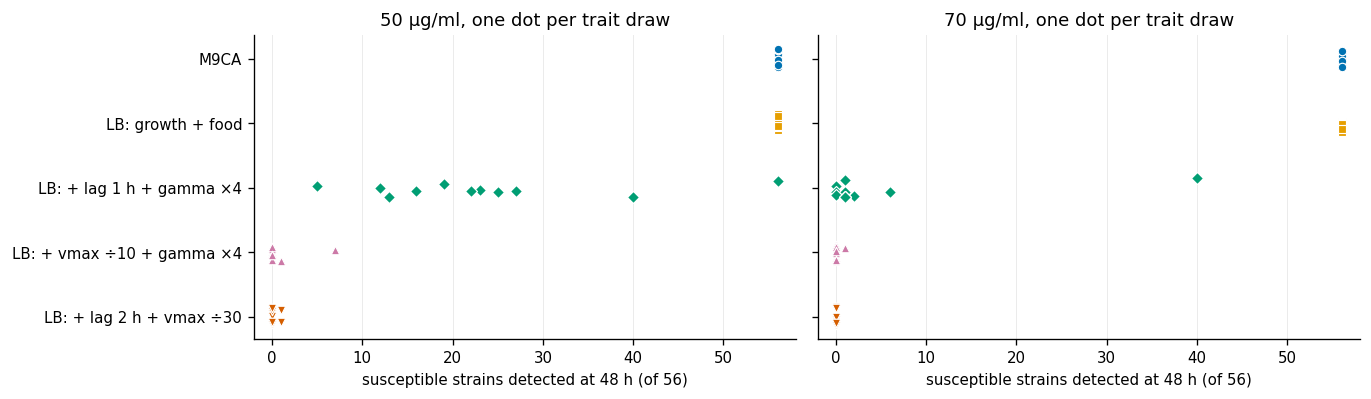

In [10]:
SEEDS = [1, 2, 3, 5, 7, 11, 13, 17, 23, 42, 99, 123]
rob = []
for sd in SEEDS:
    ref = {d: run(seed=sd, dose=d).metrics for d in DOSES}
    for name, kw in SCEN.items():
        for dose in DOSES:
            m = run(seed=sd, dose=dose, **kw).metrics
            rob.append(dict(seed=sd, scenario=name, dose=dose, **m[KEY].to_dict(),
                            lab_like=bool(m.protected_change_4_6h < ref[dose].protected_change_4_6h
                                          and m.protected_richness < ref[dose].protected_richness)))
rob = pd.DataFrame(rob)
rob.to_csv(OUT / "06_seed_robustness.csv", index=False)
print((rob.groupby(["dose", "scenario"], sort=False)
       .agg(detected_median=("protected_richness", "median"),
            detected_min=("protected_richness", "min"), detected_max=("protected_richness", "max"),
            extinct_median=("protected_extinct", "median"),
            early_change_median=("protected_change_4_6h", "median"),
            lab_like_draws=("lab_like", "sum"))
       .round(4).to_string()))

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.4), sharey=True)
rng = np.random.default_rng(0)
for ax, dose in zip(axs, DOSES):
    for k, name in enumerate(SCEN):
        s = rob[(rob.dose == dose) & (rob.scenario == name)]
        ax.scatter(s.protected_richness, k + rng.uniform(-.15, .15, len(s)), s=26,
                   color=SC_COL[name], marker=SC_MK[name], edgecolor="white", linewidth=.7, zorder=3)
    ax.set_yticks(range(len(SCEN))); ax.set_yticklabels(list(SCEN))
    ax.set(xlim=(-2, 58), xlabel="susceptible strains detected at 48 h (of 56)",
           title=f"{dose:g} µg/ml, one dot per trait draw")
    ax.grid(axis="y", visible=False)
axs[0].invert_yaxis()
fig.tight_layout(); save(fig, "06_seed_robustness"); plt.show()

### Robustness

- M9CA and LB's growth + food keep all 56 strains in all 12 trait draws at both doses.
- **LB + `vmax` ÷ 10 + `gamma` × 4** and **LB + lag 2 h + `vmax` ÷ 30** are lab-like in 12 of 12 draws at both doses. The first loses strains to extinction (median 41.5 extinct at 50 µg/ml), the second to dominance (median 0 extinct).
- **LB + lag 1 h + `gamma` × 4** is lab-like in 11 of 12 draws at 50 µg/ml and 12 of 12 at 70, but how many strains remain detectable varies widely between draws (5–56 at 50 µg/ml).

## Summary

1. **LB's faster growth and richer food alone make the model's LB community recover *better*, not worse.** The culture is so dense when the drug arrives that k30 clears it in minutes, and the cells soon stop growing and become tolerant. This contradicts the lab result, so the model needs at least one further LB-specific difference.
2. **No single plausible difference reproduces the LB result**; it takes a 12-fold rise in killing per growth or a 4 h lag. **Moderate differences in two properties do** (for example killing × 4 with enzyme ÷ 10 or with a 1 h lag).
3. **Killing per unit growth (`gamma`) is the strongest lever,** especially for the faster 4 → 6 h decline that the lab observed. Lower enzyme activity per cell and a lag phase are secondary. Susceptible IC50 has no effect at these doses.
4. **The lab's richness drop can arise from true extinction or from k30's dominance hiding the others below detection,** and the two point to different mechanisms.

**Measurements that would pin this down**

| Unknown | Measurement |
|---|---|
| growth, lag, density at drug addition | growth curves of the community in each medium; OD at the 4 h drug addition |
| `gamma` (killing per growth) | time-kill curves of the all-sensitive community in each medium, normalized by its growth rate |
| `vmax` (enzyme per OD) | carbenicillin clearance by k30 alone in each medium (bioassay or nitrocefin), per OD |
| extinct versus undetected | absolute barcode abundances at 48 h (spike-in standard or qPCR) |

**Limits.** All strains share one lag and one `gamma`; in reality these may differ between strains and media. The LB values of the unknowns are assumed, not measured. The model is deterministic and well mixed.